In [7]:
# ==============================================================================
# GIAI ĐOẠN 1: THU THẬP VÀ ĐÁNH GIÁ DỮ LIỆU BAN ĐẦU
# ==============================================================================

import os
import glob
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import RobustScaler
from IPython.display import display

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 11

# 1. Tải dữ liệu tự động từ Kaggle (kèm link dự phòng chống lỗi khi Run All trên Colab)
df_raw = None
try:
    import kagglehub
    for slug in ["muhammetvarli/laptop-price", "muhammetvarl/laptop-price"]:
        try:
            path = kagglehub.dataset_download(slug)
            csv_files = glob.glob(os.path.join(path, "*.csv"))
            if csv_files:
                df_raw = pd.read_csv(csv_files[0], encoding='latin-1')
                break
        except Exception:
            continue
except Exception:
    pass

if df_raw is None:
    backup_urls = [
        "https://raw.githubusercontent.com/muhammetvarli/Laptop-Price-Prediction/master/laptop_price.csv",
        "https://raw.githubusercontent.com/Manishms18/Laptop-Price-Predictor/master/laptop_price.csv"
    ]
    for url in backup_urls:
        try:
            df_raw = pd.read_csv(url, encoding='latin-1')
            break
        except Exception:
            continue

# 2. Kiểm tra kích thước và 5 dòng dữ liệu đầu tiên
print(f"Kích thước dữ liệu gốc: {df_raw.shape[0]} dòng x {df_raw.shape[1]} cột")
display(df_raw.head())

# 3. Rà soát cấu trúc, kiểu dữ liệu và tỷ lệ giá trị khuyết thiếu (Missing values)
status_table = pd.DataFrame({
    'Kiểu dữ liệu (Dtype)': df_raw.dtypes,
    'Số lượng Missing': df_raw.isnull().sum(),
    'Tỷ lệ Missing (%)': (df_raw.isnull().sum() / len(df_raw) * 100).round(2),
    'Số giá trị Unique': df_raw.nunique(),
    'Giá trị mẫu': df_raw.iloc[0].values
})
print("\n[Giai đoạn 1] Bảng kiểm tra hiện trạng dữ liệu:")
display(status_table)

# 4. Kiểm tra số lượng bản ghi trùng lặp (Duplicates)
id_col = 'laptop_ID' if 'laptop_ID' in df_raw.columns else None
dup_specs = df_raw.drop(columns=[id_col]).duplicated().sum() if id_col else df_raw.duplicated().sum()
print(f"Số bản ghi trùng lặp thông số kỹ thuật (bỏ qua cột ID): {dup_specs}")

Using Colab cache for faster access to the 'laptop-price' dataset.
Kích thước dữ liệu gốc: 1303 dòng x 13 cột


,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60



[Giai đoạn 1] Bảng kiểm tra hiện trạng dữ liệu:


,Kiểu dữ liệu (Dtype),Số lượng Missing,Tỷ lệ Missing (%),Số giá trị Unique,Giá trị mẫu
laptop_ID,int64,0,0.0,1303,1
Company,object,0,0.0,19,Apple
Product,object,0,0.0,618,MacBook Pro
TypeName,object,0,0.0,6,Ultrabook
Inches,float64,0,0.0,18,13.3
ScreenResolution,object,0,0.0,40,IPS Panel Retina Display 2560x1600
Cpu,object,0,0.0,118,Intel Core i5 2.3GHz
Ram,object,0,0.0,9,8GB
Memory,object,0,0.0,39,128GB SSD
Gpu,object,0,0.0,110,Intel Iris Plus Graphics 640


Số bản ghi trùng lặp thông số kỹ thuật (bỏ qua cột ID): 28


[Giai đoạn 2] Kích thước dữ liệu sau khi xóa trùng lặp: (1275, 12)

[Giai đoạn 2] Bảng đối chiếu Median vs Mean và thống kê Ngoại lệ (Outliers) theo IQR:


,Biến số,Median (Được chọn),Mean (Bị lệch do Outliers),Độ lệch (Skewness),IQR,Ngưỡng dưới (Lower),Ngưỡng trên (Upper),Số lượng Outliers,Tỷ lệ Outliers (%)
0,Inches,15.60,15.02,-0.44,1.60,11.60,18.00,37,2.90
1,Ram_GB,8.00,8.44,2.70,4.00,-2.00,14.00,219,17.18
2,Weight_kg,2.04,2.04,1.15,0.81,0.28,3.53,45,3.53
3,PPI,141.21,146.98,2.04,30.01,82.33,202.36,114,8.94
4,CPU_Freq_GHz,2.50,2.30,-0.84,0.70,0.95,3.75,2,0.16
5,Price_euros,989.00,1134.97,1.51,887.50,-722.25,2827.75,28,2.20


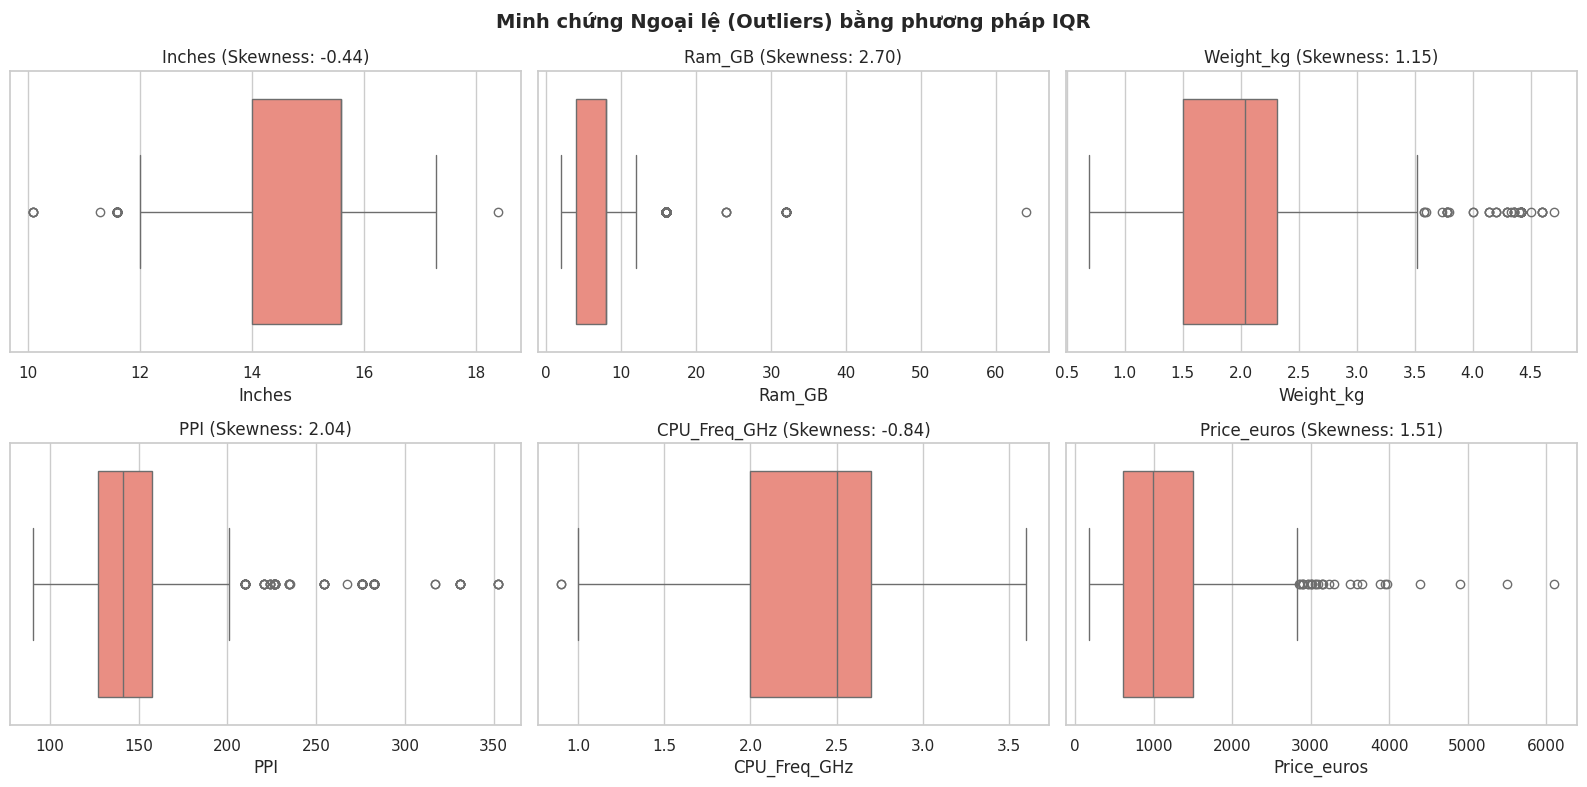


[Giai đoạn 2] 5 dòng đầu của dữ liệu số sau khi chuẩn hóa bằng RobustScaler (dựa trên Median & IQR):


,Inches_scaled,Ram_GB_scaled,Weight_kg_scaled,PPI_scaled,CPU_Freq_GHz_scaled,Price_euros_scaled
0,-1.4375,0.0,-0.827160,2.858047,-0.285714,0.395144
1,-1.4375,0.0,-0.864198,-0.450850,-1.000000,-0.101476
2,0.0000,0.0,-0.222222,0.000000,0.000000,-0.466479
3,-0.1250,2.0,-0.259259,2.643119,0.285714,1.744732
4,-1.4375,0.0,-0.827160,2.858047,0.857143,0.917859


In [8]:
# ==============================================================================
# GIAI ĐOẠN 2: TIỀN XỬ LÝ VÀ LÀM SẠCH DỮ LIỆU
# ==============================================================================

df = df_raw.copy()

# 1. Xử lý dữ liệu trùng lặp và bỏ cột định danh laptop_ID
if id_col:
    df.drop(columns=[id_col], inplace=True)
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
print(f"[Giai đoạn 2] Kích thước dữ liệu sau khi xóa trùng lặp: {df.shape}")

# 2. Xử lý sai định dạng: Chuyển cột 'Ram' (GB) và 'Weight' (kg) từ chuỗi sang kiểu số
df['Ram_GB'] = df['Ram'].astype(str).str.replace('GB', '', regex=False).str.strip().astype(int)
df['Weight_kg'] = df['Weight'].astype(str).str.replace('kg', '', regex=False).str.strip().astype(float)

# 3. Trích xuất đặc trưng kỹ thuật từ các cột văn bản
df['Touchscreen'] = df['ScreenResolution'].astype(str).apply(lambda x: 1 if 'Touchscreen' in x else 0)
df['IPS_Panel'] = df['ScreenResolution'].astype(str).apply(lambda x: 1 if 'IPS' in x else 0)
res_split = df['ScreenResolution'].astype(str).str.extract(r'(\d+)x(\d+)')
df['Res_Width'] = res_split[0].astype(int)
df['Res_Height'] = res_split[1].astype(int)
df['PPI'] = (((df['Res_Width']**2 + df['Res_Height']**2)**0.5) / df['Inches']).round(2)

def parse_cpu_brand(cpu_text):
    for tier in ['Intel Core i7', 'Intel Core i5', 'Intel Core i3']:
        if tier in cpu_text:
            return tier
    return 'Other Intel' if cpu_text.startswith('Intel') else 'AMD Processor'

df['CPU_Category'] = df['Cpu'].astype(str).apply(parse_cpu_brand)
df['CPU_Freq_GHz'] = df['Cpu'].astype(str).str.extract(r'(\d+(?:\.\d+)?)\s*GHz')[0].astype(float)

# [LỰA CHỌN KỸ THUẬT 1]: Dùng MEDIAN (không dùng Mean) để điền giá trị thiếu nhằm tránh nhiễu bởi Outliers
df['CPU_Freq_GHz'].fillna(df['CPU_Freq_GHz'].median(), inplace=True)

df['Has_SSD'] = df['Memory'].astype(str).apply(lambda x: 1 if ('SSD' in x or 'Flash Storage' in x) else 0)
df['GPU_Brand'] = df['Gpu'].astype(str).apply(lambda x: x.split()[0])
df['OS_Group'] = df['OpSys'].astype(str).apply(
    lambda x: 'Windows' if 'Windows' in x else ('Mac' if 'Mac' in x or 'macOS' in x else ('Linux' if 'Linux' in x else 'No OS / Other'))
)

# 4. Phát hiện Outliers bằng phương pháp IQR & Chứng minh tại sao chọn MEDIAN thay vì MEAN
num_cols = ['Inches', 'Ram_GB', 'Weight_kg', 'PPI', 'CPU_Freq_GHz', 'Price_euros']
outlier_stats = []
for col in num_cols:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_b, upper_b = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    outliers_cnt = df[(df[col] < lower_b) | (df[col] > upper_b)].shape[0]
    outlier_stats.append({
        'Biến số': col,
        'Median (Được chọn)': round(df[col].median(), 2),
        'Mean (Bị lệch do Outliers)': round(df[col].mean(), 2),
        'Độ lệch (Skewness)': round(df[col].skew(), 2),
        'IQR': round(IQR, 2),
        'Ngưỡng dưới (Lower)': round(lower_b, 2),
        'Ngưỡng trên (Upper)': round(upper_b, 2),
        'Số lượng Outliers': outliers_cnt,
        'Tỷ lệ Outliers (%)': round(outliers_cnt / len(df) * 100, 2)
    })

print("\n[Giai đoạn 2] Bảng đối chiếu Median vs Mean và thống kê Ngoại lệ (Outliers) theo IQR:")
display(pd.DataFrame(outlier_stats))

# Biểu đồ Boxplot minh chứng Outliers trên các biến định lượng
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
fig.suptitle('Minh chứng Ngoại lệ (Outliers) bằng phương pháp IQR', fontsize=14, fontweight='bold')
for idx, col in enumerate(num_cols):
    r, c = divmod(idx, 3)
    sns.boxplot(x=df[col], ax=axes[r, c], color='salmon')
    axes[r, c].set_title(f"{col} (Skewness: {df[col].skew():.2f})")
plt.tight_layout()
plt.savefig("Hinh_0_Boxplot_Outliers.png", dpi=300, bbox_inches='tight')
plt.show()

# 5. Áp dụng Kỹ thuật Chuẩn hóa (Scaling) và Mã hóa (Encoding)
df['Log_Price'] = np.log1p(df['Price_euros'])
scaler = RobustScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df[num_cols]), columns=[f"{c}_scaled" for c in num_cols], index=df.index)
df_encoded = pd.get_dummies(df, columns=['TypeName', 'CPU_Category', 'GPU_Brand', 'OS_Group'], drop_first=True, dtype=int)

print("\n[Giai đoạn 2] 5 dòng đầu của dữ liệu số sau khi chuẩn hóa bằng RobustScaler (dựa trên Median & IQR):")
display(df_scaled.head())

[Giai đoạn 3] Bảng kết quả kiểm định giả thuyết thống kê:


,Giả thuyết kiểm định,Phương pháp,Giá trị thống kê,p-value,Kết luận (alpha=0.05)
0,Giá laptop có SSD vs Không có SSD,Welch's T-test,22.7561,2.2232e-96,Bác bỏ H0 (Khác biệt có ý nghĩa thống kê)
1,Giá bán giữa các phân khúc (TypeName),One-Way ANOVA,155.7532,3.9101e-129,Bác bỏ H0 (Khác biệt có ý nghĩa thống kê)
2,Tương quan giữa Dung lượng RAM và Giá bán,Pearson Correlation,0.7403,9.1329e-222,Bác bỏ H0 (Tương quan thuận rất mạnh)


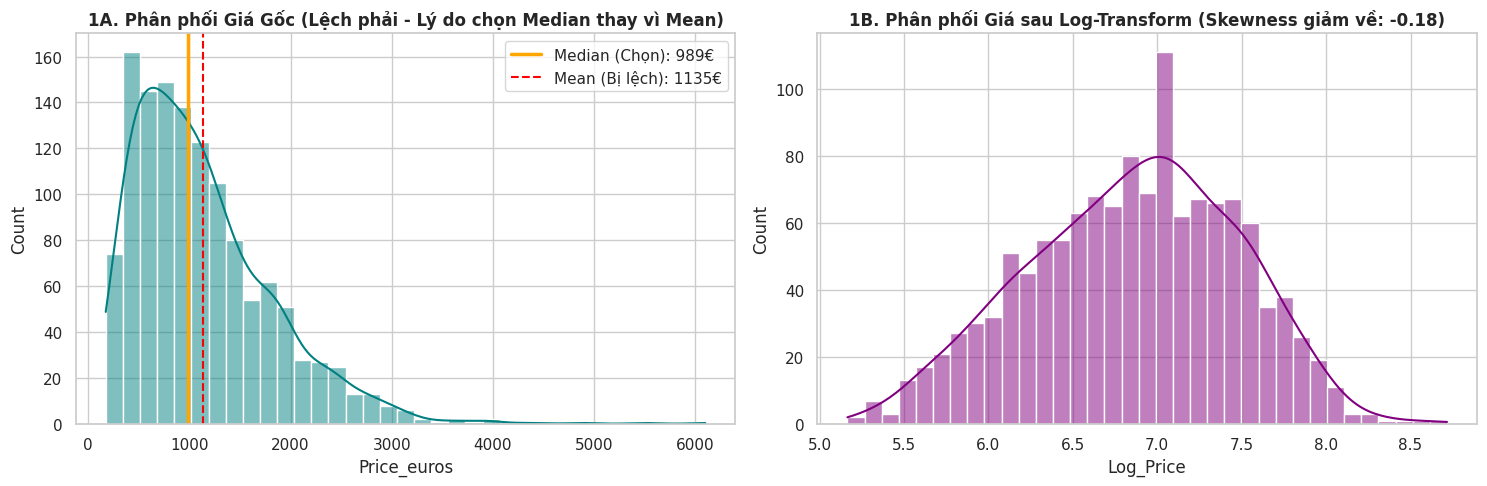

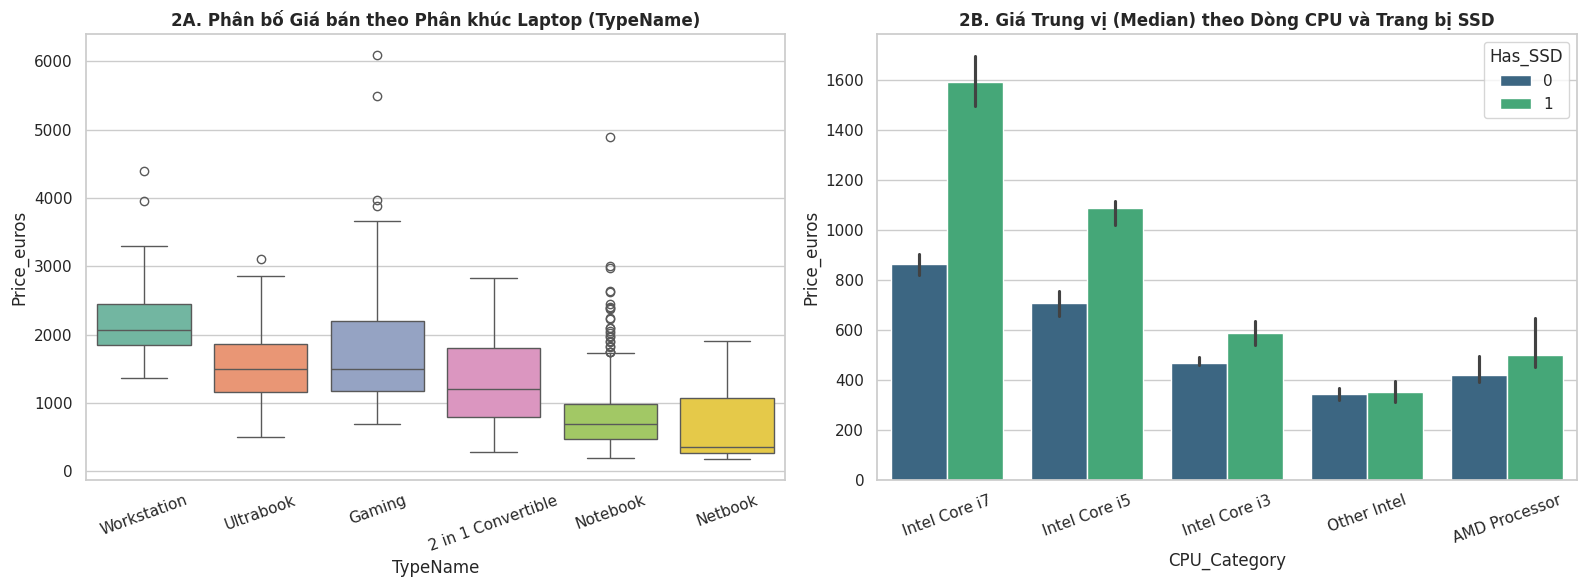

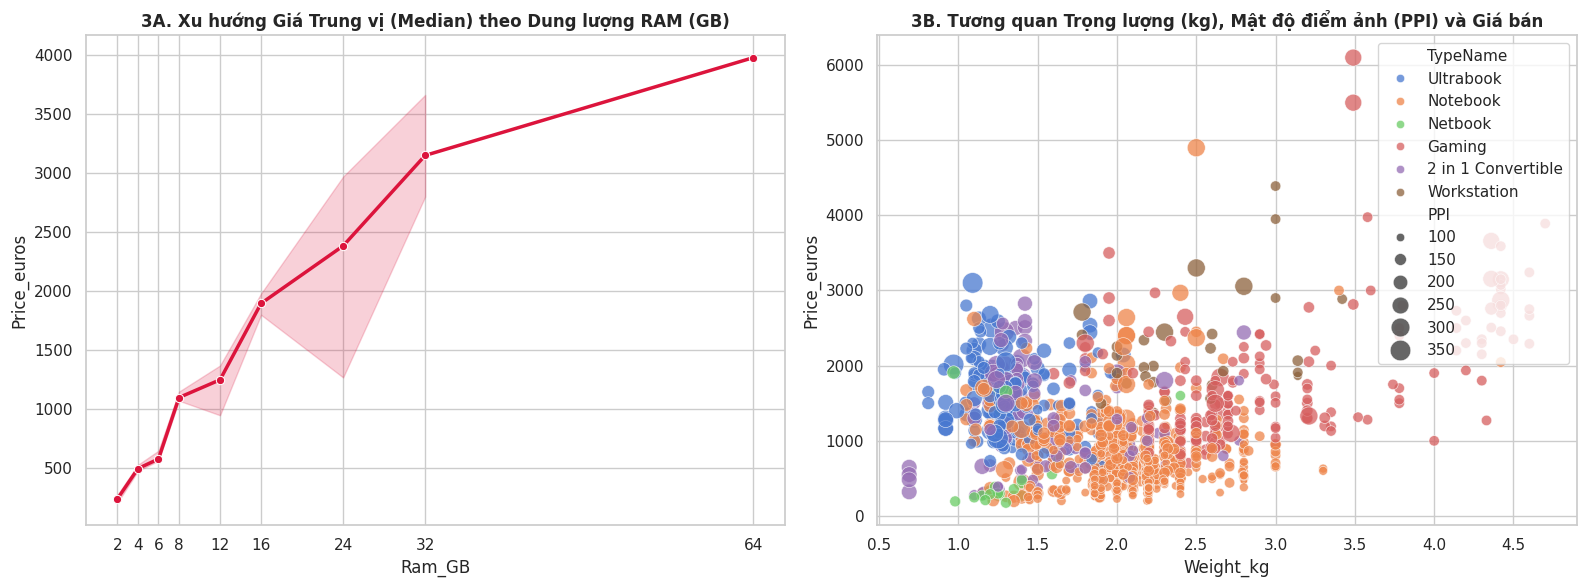

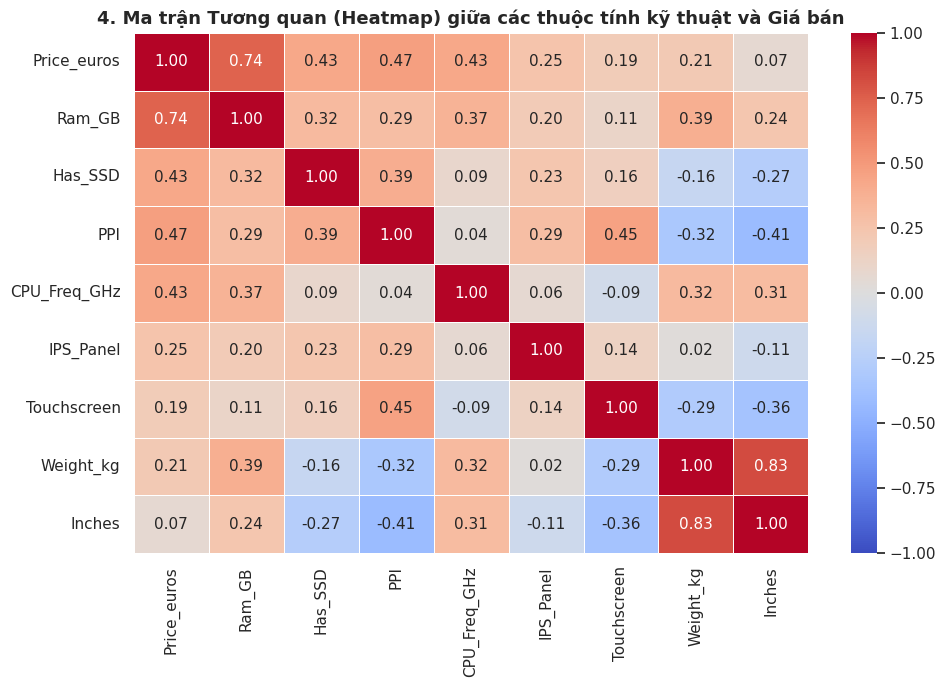

In [9]:
# ==============================================================================
# GIAI ĐOẠN 3: PHÂN TÍCH, KIỂM ĐỊNH GIẢ THUYẾT VÀ TRỰC QUAN HÓA
# ==============================================================================

# 1. Kiểm định giả thuyết thống kê
t_stat, p_val_ssd = stats.ttest_ind(df[df['Has_SSD'] == 1]['Price_euros'], df[df['Has_SSD'] == 0]['Price_euros'], equal_var=False)
f_stat, p_val_anova = stats.f_oneway(*[grp['Price_euros'].values for _, grp in df.groupby('TypeName')])
r_ram, p_val_ram = stats.pearsonr(df['Ram_GB'], df['Price_euros'])

hypothesis_table = pd.DataFrame([
    {'Giả thuyết kiểm định': 'Giá laptop có SSD vs Không có SSD', 'Phương pháp': "Welch's T-test", 'Giá trị thống kê': round(t_stat, 4), 'p-value': f"{p_val_ssd:.4e}", 'Kết luận (alpha=0.05)': 'Bác bỏ H0 (Khác biệt có ý nghĩa thống kê)'},
    {'Giả thuyết kiểm định': 'Giá bán giữa các phân khúc (TypeName)', 'Phương pháp': 'One-Way ANOVA', 'Giá trị thống kê': round(f_stat, 4), 'p-value': f"{p_val_anova:.4e}", 'Kết luận (alpha=0.05)': 'Bác bỏ H0 (Khác biệt có ý nghĩa thống kê)'},
    {'Giả thuyết kiểm định': 'Tương quan giữa Dung lượng RAM và Giá bán', 'Phương pháp': 'Pearson Correlation', 'Giá trị thống kê': round(r_ram, 4), 'p-value': f"{p_val_ram:.4e}", 'Kết luận (alpha=0.05)': 'Bác bỏ H0 (Tương quan thuận rất mạnh)'}
])
print("[Giai đoạn 3] Bảng kết quả kiểm định giả thuyết thống kê:")
display(hypothesis_table)

# 2. Hệ thống biểu đồ trực quan hóa
# Biểu đồ 1: So sánh phân phối Giá gốc và Giá sau khi biến đổi Logarit (Histogram & KDE)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(df['Price_euros'], kde=True, ax=ax[0], color='teal', bins=35)
ax[0].axvline(df['Price_euros'].median(), color='orange', linestyle='-', linewidth=2.5, label=f"Median (Chọn): {df['Price_euros'].median():.0f}€")
ax[0].axvline(df['Price_euros'].mean(), color='red', linestyle='--', linewidth=1.5, label=f"Mean (Bị lệch): {df['Price_euros'].mean():.0f}€")
ax[0].set_title('1A. Phân phối Giá Gốc (Lệch phải - Lý do chọn Median thay vì Mean)', fontweight='bold')
ax[0].legend()

sns.histplot(df['Log_Price'], kde=True, ax=ax[1], color='purple', bins=35)
ax[1].set_title(f"1B. Phân phối Giá sau Log-Transform (Skewness giảm về: {df['Log_Price'].skew():.2f})", fontweight='bold')
plt.tight_layout()
plt.savefig("Hinh_1_Phan_Phoi_Gia.png", dpi=300, bbox_inches='tight')
plt.show()

# Biểu đồ 2: Phân bố Giá theo Phân khúc máy (Boxplot) & Giá trung vị theo CPU + SSD (Barplot)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
order_type = df.groupby('TypeName')['Price_euros'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='TypeName', y='Price_euros', order=order_type, ax=ax[0], palette='Set2')
ax[0].set_title('2A. Phân bố Giá bán theo Phân khúc Laptop (TypeName)', fontweight='bold')
ax[0].tick_params(axis='x', rotation=20)

cpu_order = ['Intel Core i7', 'Intel Core i5', 'Intel Core i3', 'Other Intel', 'AMD Processor']
sns.barplot(data=df, x='CPU_Category', y='Price_euros', hue='Has_SSD', order=cpu_order, estimator=np.median, ax=ax[1], palette='viridis')
ax[1].set_title('2B. Giá Trung vị (Median) theo Dòng CPU và Trang bị SSD', fontweight='bold')
ax[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.savefig("Hinh_2_Phan_Khuc_CPU_SSD.png", dpi=300, bbox_inches='tight')
plt.show()

# Biểu đồ 3: Đường xu hướng RAM (Line Plot) & Tương quan đa biến Weight - PPI - Price (Scatter Plot)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.lineplot(data=df, x='Ram_GB', y='Price_euros', estimator=np.median, marker='o', linewidth=2.5, ax=ax[0], color='crimson')
ax[0].set_title('3A. Xu hướng Giá Trung vị (Median) theo Dung lượng RAM (GB)', fontweight='bold')
ax[0].set_xticks(sorted(df['Ram_GB'].unique()))

sns.scatterplot(data=df, x='Weight_kg', y='Price_euros', hue='TypeName', size='PPI', sizes=(30, 220), alpha=0.75, ax=ax[1])
ax[1].set_title('3B. Tương quan Trọng lượng (kg), Mật độ điểm ảnh (PPI) và Giá bán', fontweight='bold')
plt.tight_layout()
plt.savefig("Hinh_3_RAM_PPI_Weight.png", dpi=300, bbox_inches='tight')
plt.show()

# Biểu đồ 4: Ma trận tương quan (Correlation Heatmap)
plt.figure(figsize=(10, 7))
corr_cols = ['Price_euros', 'Ram_GB', 'Has_SSD', 'PPI', 'CPU_Freq_GHz', 'IPS_Panel', 'Touchscreen', 'Weight_kg', 'Inches']
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('4. Ma trận Tương quan (Heatmap) giữa các thuộc tính kỹ thuật và Giá bán', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("Hinh_4_Heatmap_Tuong_Quan.png", dpi=300, bbox_inches='tight')
plt.show()

In [10]:
# ==============================================================================
# BẢNG SỐ LIỆU TỔNG HỢP THEO MEDIAN PHỤC VỤ VIẾT BÁO CÁO GIAI ĐOẠN 4
# ==============================================================================

segment_report = df.groupby('TypeName').agg(
    So_Luong_May=('Price_euros', 'count'),
    Gia_Trung_Vi_Median_EUR=('Price_euros', lambda x: round(x.median(), 2)),
    IQR_Gia_EUR=('Price_euros', lambda x: round(x.quantile(0.75) - x.quantile(0.25), 2)),
    RAM_Pho_Bien_GB=('Ram_GB', lambda x: x.mode()[0]),
    Ty_Le_Co_SSD_Pct=('Has_SSD', lambda x: round(x.mean() * 100, 1)),
    PPI_Trung_Vi=('PPI', lambda x: round(x.median(), 1)),
    Trong_Luong_Trung_Vi_kg=('Weight_kg', lambda x: round(x.median(), 2))
).sort_values(by='Gia_Trung_Vi_Median_EUR', ascending=False)

print("[Số liệu dẫn chứng cho Giai đoạn 4] Bảng tổng hợp theo Trung vị (Median) và IQR cho từng phân khúc:")
display(segment_report)

# Xuất bảng dữ liệu đã làm sạch và mã hóa ra file CSV
df_encoded.to_csv("laptop_price_cleaned_processed.csv", index=False)
print("\nĐã xuất file 'laptop_price_cleaned_processed.csv' thành công!")

[Số liệu dẫn chứng cho Giai đoạn 4] Bảng tổng hợp theo Trung vị (Median) và IQR cho từng phân khúc:


,So_Luong_May,Gia_Trung_Vi_Median_EUR,IQR_Gia_EUR,RAM_Pho_Bien_GB,Ty_Le_Co_SSD_Pct,PPI_Trung_Vi,Trong_Luong_Trung_Vi_kg
TypeName,,,,,,,
Workstation,29,2064.9,590.00,8,82.8,141.2,2.31
Ultrabook,194,1499.0,709.22,8,97.9,165.6,1.30
Gaming,205,1492.8,1030.00,16,86.8,141.2,2.70
2 in 1 Convertible,117,1199.0,1000.99,8,89.7,165.6,1.42
Notebook,707,695.0,503.56,4,54.9,141.2,2.10
Netbook,23,355.0,797.50,4,100.0,135.1,1.26



Đã xuất file 'laptop_price_cleaned_processed.csv' thành công!
